In [30]:
# box 1

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils
import torch.utils.data
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from math import pi
import pandas as pd

In [31]:
# box 2

#--- ADDED CODE ---
from google.colab import files
files.upload()
#--- ADDED CODE ---

inp_u1 = pd.read_csv(r'data_theta_x.csv', header = None)
inputs_u1 = inp_u1.to_numpy()

x = inputs_u1[:, 0].astype(np.float32)
t = inputs_u1[:, 1].astype(np.float32)
x = torch.from_numpy(x.reshape(-1, 1))
t = torch.from_numpy(t.reshape(-1,1))

test = torch.cat([x, t], 1)
#--- ADDED CODE ---
train_inputs = test.clone()      # (x, t) pairs from the CSV
#--- ADDED CODE ---
output = inputs_u1[:, 2].astype(np.float32)
output = torch.from_numpy(output)

# theta_x1 = inputs_u1[:,0].astype(np.float32)
# theta_x2 = inputs_u1[:,1].astype(np.float32)
# theta_x3 = inputs_u1[:,2].astype(np.float32)
# theta_x4 = inputs_u1[:,3].astype(np.float32)
# theta_x5 = inputs_u1[:,4].astype(np.float32)

# theta_x1 = torch.from_numpy(theta_x1)
# theta_x2 = torch.from_numpy(theta_x2)
# theta_x3 = torch.from_numpy(theta_x3)
# theta_x4 = torch.from_numpy(theta_x4)
# theta_x5 = torch.from_numpy(theta_x5)
# theta_x1.shape

In [32]:
# box 3

# Define the exact solution
def exact_solution_p(x, t):
    return (0.5*pi*torch.cos(x)+(x-pi*0.5))*torch.cos(t)

def initial_condition_p(x):
    return 0.5*pi*torch.cos(x) + (x - pi*0.5)

def initial_condition_p_t(x):
    return 0.0*pi*torch.cos(x)

In [33]:
# box 4

# assigning number of points
initial_pts = 2000
left_boundary_pts = 2000
right_boundary_pts = 2000
residual_pts = 10000

x_interior = pi*torch.rand((residual_pts, 1))
t_interior = torch.rand((residual_pts, 1))
interior = torch.cat([x_interior, t_interior],1)

In [34]:
# box 5

class NeuralNet(nn.Module):

    def __init__(self, input_dimension, output_dimension, n_hidden_layers, neurons):
        super(NeuralNet, self).__init__()
        # Number of input dimensions n
        self.input_dimension = input_dimension
        # Number of output dimensions m
        self.output_dimension = output_dimension
        # Number of neurons per layer
        self.neurons = neurons
        # Number of hidden layers
        self.n_hidden_layers = n_hidden_layers
        # Activation function
        self.activation = nn.Tanh()

        self.input_layer = nn.Linear(self.input_dimension, self.neurons)
        self.hidden_layers = nn.ModuleList([nn.Linear(self.neurons, self.neurons) for _ in range(n_hidden_layers)])
        self.output_layer = nn.Linear(self.neurons, self.output_dimension)

    def forward(self, x):
        # The forward function performs the set of affine and non-linear transformations defining the network
        # (see equation above)
        x = self.activation(self.input_layer(x))
        for k, l in enumerate(self.hidden_layers):
            x = self.activation(l(x))
        return self.output_layer(x)

In [56]:
# box 6

# Type of optimizer (ADAM or LBFGS)
opt_type = "LBFGS"

manualSeed = 1

#np.random.seed(manualSeed)
#random.seed(manualSeed)
torch.manual_seed(manualSeed)

x_init = pi*torch.rand((initial_pts,1)) # initial pts
t_init = 0*x_init
init =  torch.cat([x_init, t_init],1)
p_init = initial_condition_p(init[:,0]).reshape(-1, 1)



p_t_init = initial_condition_p_t(init[:,0]).reshape(-1, 1)

xb_left = torch.zeros((left_boundary_pts, 1)) # left spatial boundary
tb_left = torch.rand((left_boundary_pts, 1)) #
b_left = torch.cat([xb_left, tb_left ],1)

p_b_l = exact_solution_p(xb_left, tb_left)

xb_right = pi*torch.ones((right_boundary_pts, 1)) # right spatial boundary
tb_right = torch.rand((right_boundary_pts, 1)) # right boundary pts
b_right = torch.cat([xb_right, tb_right ],1)
p_b_r = exact_solution_p(xb_right, tb_right)


# x_interior = pi*torch.rand((residual_pts, 1))
# t_interior = torch.rand((residual_pts, 1))
# interior = torch.cat([x_interior, t_interior],1)





training_set = DataLoader(torch.utils.data.TensorDataset(init, p_init, p_t_init, b_left,  b_right), batch_size=2000, shuffle=False)

In [57]:
# box 7

#--- ADDED CODE ---
class HardConstraintNet(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, xt):
        x, t = xt[:, 0:1], xt[:, 1:2]
        g = initial_condition_p(x)                    # 0.5*pi*cos(x) + (x - pi/2)
        return g + t**2 * x * (pi - x) * self.net(xt)

HARD_network = HardConstraintNet(
    NeuralNet(input_dimension=2, output_dimension=1, n_hidden_layers=4, neurons=20)
)
#--- ADDED CODE ---

# Model definition
#HARD_network = NeuralNet(input_dimension = init.shape[1], output_dimension = 1, n_hidden_layers=4, neurons=20)
my_network = NeuralNet(input_dimension = init.shape[1], output_dimension = 1, n_hidden_layers=4, neurons=20)

In [58]:
# box 8

def init_xavier(model, retrain_seed):
    torch.manual_seed(retrain_seed)
    def init_weights(m):
        if type(m) == nn.Linear and m.weight.requires_grad and m.bias.requires_grad:
            g = nn.init.calculate_gain('tanh')
            torch.nn.init.xavier_uniform_(m.weight, gain=g)
            #torch.nn.init.xavier_normal_(m.weight, gain=g)
            m.bias.data.fill_(0)
    model.apply(init_weights)

# Random Seed for weight initialization
retrain = 128
# Xavier weight initialization
init_xavier(my_network, retrain)
#print(my_network(init))

In [59]:
# box 9

if opt_type == "ADAM":
    optimizer_ = optim.Adam(my_network.parameters(), lr=0.001)
elif opt_type == "LBFGS":
    optimizer_ = optim.LBFGS(my_network.parameters(), lr=0.1, max_iter=1, max_eval=50000, tolerance_change=1.0 * np.finfo(float).eps)
else:
    raise ValueError("Optimizer not recognized")

if opt_type == "ADAM":
    optimizer_ = optim.Adam(HARD_network.parameters(), lr=0.001)
elif opt_type == "LBFGS":
    optimizer_ = optim.LBFGS(HARD_network.parameters(), lr=0.1, max_iter=1, max_eval=50000, tolerance_change=1.0 * np.finfo(float).eps)
else:
    raise ValueError("Optimizer not recognized")

In [60]:
# box 10

# data_pts = 2000

# x_1 = 0*torch.ones((data_pts)).reshape(-1,1)
# x_2 = 0.25*pi*torch.ones((data_pts)).reshape(-1,1)
# x_3 = 0.5*pi*torch.ones((data_pts)).reshape(-1,1)
# x_4 = 0.75*pi*torch.ones((data_pts)).reshape(-1,1)
# x_5 = pi*torch.ones((data_pts)).reshape(-1,1)

# t_data_pts = torch.rand((data_pts, 1))

# fir_loc = torch.cat([x_1, t_data_pts],1)
# sec_loc = torch.cat([x_2, t_data_pts],1)
# thr_loc = torch.cat([x_3, t_data_pts],1)
# fou_loc = torch.cat([x_4, t_data_pts],1)
# fif_loc = torch.cat([x_5, t_data_pts],1)

In [61]:
# box 11

def fit(model, training_set, interior, num_epochs, optimizer, p, verbose=True):
    history = list()

    # Loop over epochs
    for epoch in range(num_epochs):
        if verbose: print("################################ ", epoch, " ################################")

        running_loss = list([0])

        # Loop over batches
        for j, (initial, w_initial, w_initial_t, bd_left,  bd_right) in enumerate(training_set):

            def closure():
                # zero the parameter gradients
                optimizer.zero_grad()
                # for initial
                initial.requires_grad = True
                w_initial_pred_ = model(initial)
                p_initial_pred_ = w_initial_pred_.reshape(-1,1)
#                 p_initial_pred_ = w_initial_pred_[:,1].reshape(-1,1)


                # with derivative
                inpu = torch.ones(initial_pts, 1 )

                grad_p_ini = torch.autograd.grad(p_initial_pred_, initial, grad_outputs=inpu, create_graph=True, allow_unused=True)[0]

                p_initial_t = grad_p_ini[:, 1]


#                 grad_p_ini = torch.autograd.grad(p_initial_pred_, initial, grad_outputs=inpu, create_graph=True)[0]

#                 p_initial_t = grad_p_ini[:, 1]


                # for left boundary
                w_bd_left_pred_ = model(bd_left)
                p_bd_left_pred_ = w_bd_left_pred_.reshape(-1,1)
#                 p_bd_left_pred_ = w_bd_left_pred_[:,1].reshape(-1,1)
                # for right boundary
                w_bd_right_pred_ = model(bd_right)
                p_bd_right_pred_ = w_bd_right_pred_.reshape(-1,1)
#                 p_bd_right_pred_ = w_bd_right_pred_[:,1].reshape(-1,1)

#                 # residual calculation
#                 fir_loc.requires_grad = True
#                 sec_loc.requires_grad = True
#                 thr_loc.requires_grad = True
#                 fou_loc.requires_grad = True
#                 fif_loc.requires_grad = True
#                 t_data_pts.requires_grad = True
#                 x_1.requires_grad = True
#                 x_2.requires_grad = True
#                 x_3.requires_grad = True
#                 x_4.requires_grad = True
#                 x_5.requires_grad = True


#                 w_1 = model(fir_loc)
#                 w_2 = model(sec_loc)
#                 w_3 = model(thr_loc)
#                 w_4 = model(fou_loc)
#                 w_5 = model(fif_loc)
                test.requires_grad = True
                w_1 = model(test)







                # First Location

                u_hat1 = w_1.reshape(-1,1)
                inputs = torch.ones(10000, 1 )
                grad_u_hat1 = torch.autograd.grad(u_hat1.reshape(-1,1),  test, grad_outputs=inputs, create_graph=True)[0]

                p_x1 = grad_u_hat1[:, 0].reshape(-1,1)

#                 # Second Location
#                 u_hat2 = w_2.reshape(-1,1)
#                 grad_u_hat2 = torch.autograd.grad(u_hat2.reshape(-1,1), sec_loc, grad_outputs=inputs, create_graph=True)[0]

#                 p_x2 = grad_u_hat2[:, 0].reshape(-1,1)


#                 # Third Location

#                 u_hat3 = w_3.reshape(-1,1)
#                 grad_u_hat3 = torch.autograd.grad(u_hat3.reshape(-1,1), thr_loc, grad_outputs=inputs, create_graph=True)[0]
#                 u_t3 = grad_u_hat3[:, 1].reshape(-1,1)
#                 p_x3 = grad_u_hat3[:, 0].reshape(-1,1)

#                 # Fourth Location

#                 u_hat4 = w_4.reshape(-1,1)
#                 grad_u_hat4 = torch.autograd.grad(u_hat4.reshape(-1,1), fou_loc, grad_outputs=inputs, create_graph=True)[0]

#                 p_x4 = grad_u_hat4[:, 0].reshape(-1,1)


#                 # Fifth Location

#                 u_hat5 = w_5.reshape(-1,1)
#                 grad_u_hat5 = torch.autograd.grad(u_hat5.reshape(-1,1), fif_loc, grad_outputs=inputs, create_graph=True)[0]
#                 u_t5 = grad_u_hat5[:, 1].reshape(-1,1)
#                 p_x5 = grad_u_hat5[:, 0].reshape(-1,1)

# #                 data1 = torch.mean( theta_x1.reshape(-1, )**p)
# #                 data2 = torch.mean(theta_x2.reshape(-1, )**p)
# #                 data3 = torch.mean(theta_x3.reshape(-1, )**p)
# #                 data4 = torch.mean(theta_x4.reshape(-1, )**p)
# #                 data5 = torch.mean(theta_x5.reshape(-1, )**p)






                data1 = torch.mean((p_x1.reshape(-1, ) - output.reshape(-1, ))**p)
#                 data2 = torch.mean((p_x2.reshape(-1, ) - theta_x2.reshape(-1, ))**p)
#                 data3 = torch.mean((p_x3.reshape(-1, ) - theta_x3.reshape(-1, ))**p)
#                 data4 = torch.mean((p_x4.reshape(-1, ) - theta_x4.reshape(-1, ))**p)
#                 data5 = torch.mean((p_x5.reshape(-1, ) - theta_x5.reshape(-1, ))**p)

                 # Item 1. below

                #loss2 = torch.mean((u_initial_t.reshape(-1, ) - w_initial_t.reshape(-1, ))**p)+torch.mean((u_initial_pred_.reshape(-1, ) - w_initial.reshape(-1, ))**p) + torch.mean((u_bd_left_pred_.reshape(-1,) - u_b_l.reshape(-1,))**p) + torch.mean((u_bd_right_pred_.reshape(-1,) - u_b_r.reshape(-1,))**p)

                #loss = torch.mean((u_initial_t.reshape(-1, ) - w_initial_t[:, 0].reshape(-1, ))**p)

                #loss1 = torch.mean((u_initial_t.reshape(-1, ) - w_initial_t[:,0].reshape(-1, ))**p)+torch.mean((u_initial_pred_.reshape(-1, ) - w_initial[:,0].reshape(-1, ))**p)+torch.mean((u_bd_left_pred_.reshape(-1,)- u_b_l.reshape(-1,))**p) + torch.mean((u_bd_right_pred_.reshape(-1,)- u_b_r.reshape(-1,))**p)
                loss1 = torch.mean((p_initial_pred_.reshape(-1, ) - w_initial.reshape(-1, ))**p)+ torch.mean((p_initial_t.reshape(-1, ) - w_initial_t.reshape(-1, ))**p)+torch.mean((p_bd_left_pred_.reshape(-1,)- p_b_l.reshape(-1,))**p) + torch.mean((p_bd_right_pred_.reshape(-1,)- p_b_r.reshape(-1,))**p)
#                 loss = loss1 + loss2
                #loss = torch.max(torch.abs((u_initial_pred_.reshape(-1, ) - u_initial.reshape(-1, )))) + torch.max(torch.abs((u_t.reshape(-1, ) - u_xx.reshape(-1, ))))+torch.max(torch.abs((u_bd_left_pred_.reshape(-1,)))) + torch.max(torch.abs((u_bd_right_pred_.reshape(-1,))))
                loss = loss1 + 0.1*data1
                #loss = loss1

                # Item 2. below
                loss.backward()
                # Compute average training loss over batches for the current epoch
                running_loss[0] += loss.item()
                return loss

            # Item 3. below
            optimizer.step(closure=closure)

        print('Loss: ', (running_loss[0] / len(training_set)))
        history.append(running_loss[0])

    return history

In [62]:
# box 11.5

#--- ADDED CODE ---
def hard_fit(model, xt_data, theta_data, num_epochs, optimizer, p=2, verbose=True):
    history = []
    xt = xt_data.clone().requires_grad_(True)

    for epoch in range(num_epochs):
        def closure():
            optimizer.zero_grad()
            w = model(xt)
            grad = torch.autograd.grad(w, xt, grad_outputs=torch.ones_like(w),
                                       create_graph=True)[0]
            loss = torch.mean((grad[:, 0] - theta_data.reshape(-1))**p)   # data loss only
            loss.backward()
            return loss

        loss = optimizer.step(closure)
        history.append(loss.item())
        if verbose and epoch % 100 == 0:
            print(f"epoch {epoch}  loss {loss.item():.3e}")
    return history
#--- ADDED CODE ---

In [63]:
# box 12

n_epochs = 15000

#--- ADDED CODE ---
history = hard_fit(HARD_network, train_inputs, output, n_epochs, optimizer_, p=2)
#--- ADDED CODE ---

#history = fit(my_network, training_set, interior, n_epochs, optimizer_, p=2, verbose=True )

epoch 0  loss 3.146e-01
epoch 100  loss 1.715e-03
epoch 200  loss 1.258e-03
epoch 300  loss 1.257e-03
epoch 400  loss 1.257e-03
epoch 500  loss 1.257e-03
epoch 600  loss 1.257e-03
epoch 700  loss 1.257e-03
epoch 800  loss 1.257e-03
epoch 900  loss 1.257e-03
epoch 1000  loss 1.257e-03
epoch 1100  loss 1.257e-03
epoch 1200  loss 1.257e-03
epoch 1300  loss 1.257e-03
epoch 1400  loss 1.257e-03
epoch 1500  loss 1.257e-03
epoch 1600  loss 1.257e-03
epoch 1700  loss 1.257e-03
epoch 1800  loss 1.257e-03
epoch 1900  loss 1.257e-03
epoch 2000  loss 1.257e-03
epoch 2100  loss 1.257e-03
epoch 2200  loss 1.257e-03
epoch 2300  loss 1.257e-03
epoch 2400  loss 1.257e-03
epoch 2500  loss 1.257e-03
epoch 2600  loss 1.257e-03
epoch 2700  loss 1.257e-03
epoch 2800  loss 1.257e-03
epoch 2900  loss 1.257e-03
epoch 3000  loss 1.257e-03
epoch 3100  loss 1.257e-03
epoch 3200  loss 1.257e-03
epoch 3300  loss 1.257e-03
epoch 3400  loss 1.257e-03
epoch 3500  loss 1.257e-03
epoch 3600  loss 1.257e-03
epoch 3700  l

In [64]:
# box 13

#--- ADDED CODE ---
from google.colab import files
files.upload()
#--- ADDED CODE ---

# # # # # saving and loading Model
FILE = "Rotation.pth"
#torch.save(my_network, FILE)

# # # # uncomment below when you need to test for different points
# Set weights_only=False to allow loading custom classes from a trusted file
my_network = torch.load(FILE, weights_only=False)
my_network.eval()

#--- ADDED CODE ---
torch.save(HARD_network, "Rotation_hard.pth")
HARD_network.eval()
#--- ADDED CODE ---

HardConstraintNet(
  (net): NeuralNet(
    (activation): Tanh()
    (input_layer): Linear(in_features=2, out_features=20, bias=True)
    (hidden_layers): ModuleList(
      (0-3): 4 x Linear(in_features=20, out_features=20, bias=True)
    )
    (output_layer): Linear(in_features=20, out_features=1, bias=True)
  )
)

In [65]:
# box 14

x_test = torch.linspace(0, pi, 10000).reshape(-1,1)
t_test = torch.ones((10000,1))
test = torch.cat([x_test, t_test],1)
#u_test = exact_solution_u(x_test, t_test).reshape(-1,1)
p_test = exact_solution_p(x_test, t_test).reshape(-1,1)
w_test_pred = my_network(test)
#u_test_pred = w_test_pred.reshape(-1,1)
p_test_pred = w_test_pred.reshape(-1,1)

#--- ADDED CODE ---
w_test_pred_hard = HARD_network(test)
p_test_pred_hard = w_test_pred_hard.reshape(-1,1)
#--- ADDED CODE ---

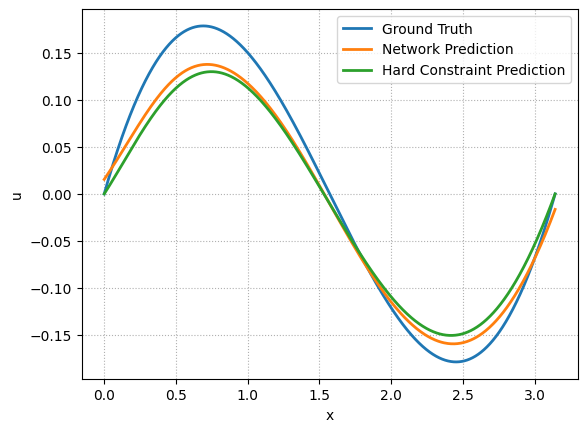

In [66]:
# box 15

plt.grid(True, which="both", ls=":")
plt.plot(x_test, p_test, label="Ground Truth",lw=2)
plt.plot(x_test, p_test_pred.detach(), label="Network Prediction",lw=2)
plt.plot(x_test, p_test_pred_hard.detach(), label="Hard Constraint Prediction",lw=2) #ADDED
plt.xlabel("x")
plt.ylabel("u")
plt.legend()

In [67]:
# box 16

#--- ADDED CODE ---
# check constraints hold exactly
with torch.no_grad():
    print((HARD_network(init) - p_init).abs().max())     # ~1e-7 (float32), IC value
    print(HARD_network(b_left).abs().max())               # 0
    print(HARD_network(b_right).abs().max())              # ~1e-7
#--- ADDED CODE ---

# Compute the relative L2 error norm (generalization error)
relative_error_test = torch.mean((p_test_pred - p_test)**2)/torch.mean(p_test**2)
HARD_relative_error_test = torch.mean((p_test_pred_hard - p_test)**2)/torch.mean(p_test**2)
#relative_error_test = torch.max(torch.abs(u_test_pred -u_test))/torch.max(torch.abs(u_test))
print("Relative Error Test: ", relative_error_test.detach().numpy()*100, "%")
print("HARD Relative Error Test: ", HARD_relative_error_test.detach().numpy()*100, "%")

tensor(0.)
tensor(0.)
tensor(0.)
Relative Error Test:  3.4867275 %
HARD Relative Error Test:  5.8398476 %


### Iterating Through Different Learning Rates

Below, we define a list of learning rates and train a fresh `HardConstraintNet` model for each rate. We will store the history and plot the loss convergence as well as final test predictions to determine which learning rate yields the best accuracy.

In [70]:
import copy

# Define the list of learning rates to search
learning_rates = [0.01, 0.001, 0.0001, 0.00001]
results = {}

# We will use fewer epochs here for a quicker sweep (e.g., 2000), but feel free to increase it.
sweep_epochs = 3000

for lr in learning_rates:
    print(f"\n--- Training with Learning Rate: {lr} ---")

    # 1. Re-initialize the underlying network and hard constraint network
    raw_net = NeuralNet(input_dimension=2, output_dimension=1, n_hidden_layers=4, neurons=20)
    init_xavier(raw_net, retrain_seed=128)
    sweep_model = HardConstraintNet(raw_net)

    # 2. Define the optimizer with the specific learning rate
    optimizer_sweep = optim.LBFGS(
        sweep_model.parameters(),
        lr=lr,
        max_iter=1,
        max_eval=50000,
        tolerance_change=1.0 * np.finfo(float).eps
    )

    # 3. Train using our hard_fit function
    history_sweep = hard_fit(sweep_model, train_inputs, output, sweep_epochs, optimizer_sweep, p=2, verbose=False)

    # 4. Evaluate on test set
    with torch.no_grad():
        sweep_pred = sweep_model(test).reshape(-1, 1)
        test_error = torch.mean((sweep_pred - p_test)**2) / torch.mean(p_test**2)
        test_error_pct = test_error.item() * 100

    print(f"Final Loss: {history_sweep[-1]:.6e} | Relative Test Error: {test_error_pct:.4f}%")

    # Save results
    results[lr] = {
        'history': history_sweep,
        'predictions': sweep_pred.detach().cpu().numpy(),
        'test_error_pct': test_error_pct
    }


--- Training with Learning Rate: 0.01 ---
Final Loss: 1.253125e-03 | Relative Test Error: 5.8394%

--- Training with Learning Rate: 0.001 ---
Final Loss: 1.292290e-03 | Relative Test Error: 5.9847%

--- Training with Learning Rate: 0.0001 ---
Final Loss: 9.462653e-03 | Relative Test Error: 6.2493%

--- Training with Learning Rate: 1e-05 ---
Final Loss: 4.286123e-01 | Relative Test Error: 699.9599%


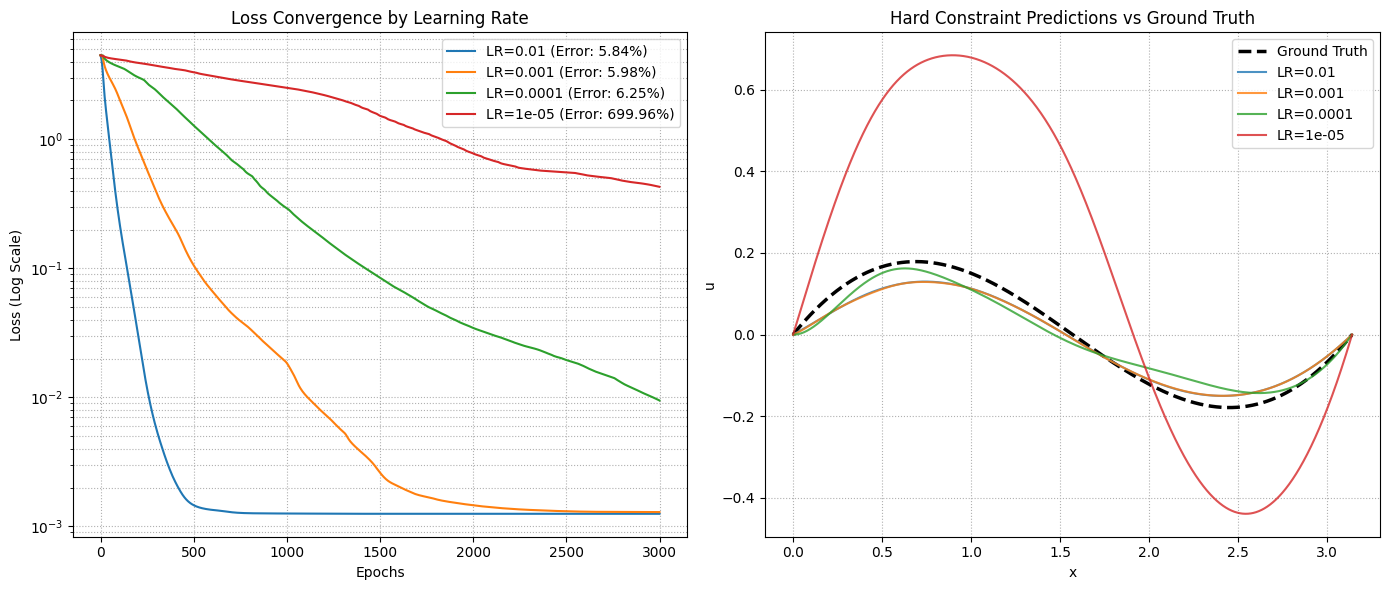

In [71]:
# Plotting the results
plt.figure(figsize=(14, 6))

# Subplot 1: Loss History Comparison
plt.subplot(1, 2, 1)
for lr, res in results.items():
    plt.plot(res['history'], label=f"LR={lr} (Error: {res['test_error_pct']:.2f}%)")
plt.yscale('log')
plt.xlabel('Epochs')
plt.ylabel('Loss (Log Scale)')
plt.title('Loss Convergence by Learning Rate')
plt.legend()
plt.grid(True, which="both", ls=":")

# Subplot 2: Predictions vs Ground Truth
plt.subplot(1, 2, 2)
plt.plot(x_test.numpy(), p_test.numpy(), 'k--', label="Ground Truth", lw=2.5)
for lr, res in results.items():
    plt.plot(x_test.numpy(), res['predictions'], label=f"LR={lr}", alpha=0.8)
plt.xlabel('x')
plt.ylabel('u')
plt.title('Hard Constraint Predictions vs Ground Truth')
plt.legend()
plt.grid(True, which="both", ls=":")

plt.tight_layout()
plt.show()

### Exploring Other Hyperparameters to Improve the Fit

Below, we can try three alternative configurations to see if we can reduce the test error below our current baseline:
1. **Configuration A:** Larger network capacity (5 hidden layers, 40 neurons each).
2. **Configuration B:** Switching to the `SiLU` (Swish) activation function instead of `Tanh`.
3. **Configuration C:** Enabling the `"strong_wolfe"` line search in the L-BFGS optimizer.

In [72]:
# We'll define a custom class variant to test different activation functions
class CustomNeuralNet(nn.Module):
    def __init__(self, input_dimension, output_dimension, n_hidden_layers, neurons, activation_fn=nn.Tanh()):
        super().__init__()
        self.activation = activation_fn
        self.input_layer = nn.Linear(input_dimension, neurons)
        self.hidden_layers = nn.ModuleList([nn.Linear(neurons, neurons) for _ in range(n_hidden_layers)])
        self.output_layer = nn.Linear(neurons, output_dimension)

    def forward(self, x):
        x = self.activation(self.input_layer(x))
        for l in self.hidden_layers:
            x = self.activation(l(x))
        return self.output_layer(x)

# Set up our experimental test-bed configurations
experiments = {
    "Baseline (4x20, Tanh)": {
        "model": HardConstraintNet(CustomNeuralNet(2, 1, 4, 20, nn.Tanh())),
        "line_search": None
    },
    "Larger Depth (5x40, Tanh)": {
        "model": HardConstraintNet(CustomNeuralNet(2, 1, 5, 40, nn.Tanh())),
        "line_search": None
    },
    "Larger Depth (6x40, Tanh)": {
        "model": HardConstraintNet(CustomNeuralNet(2, 1, 6, 20, nn.Tanh())),
        "line_search": None
    },
    "Larger Depth (7x40, Tanh)": {
        "model": HardConstraintNet(CustomNeuralNet(2, 1, 7, 20, nn.Tanh())),
        "line_search": None
    }
}

exp_results = {}
epochs_exp = 3000

for name, config in experiments.items():
    print(f"\n--- Running Experiment: {name} ---")
    model_exp = config["model"]
    init_xavier(model_exp.net, retrain_seed=128)

    # Configure L-BFGS with or without line search
    optimizer_exp = optim.LBFGS(
        model_exp.parameters(),
        lr=0.01,
        max_iter=1,
        max_eval=50000,
        tolerance_change=1.0 * np.finfo(float).eps,
        line_search_fn=config["line_search"]
    )

    # Train
    history_exp = hard_fit(model_exp, train_inputs, output, epochs_exp, optimizer_exp, p=2, verbose=False)

    # Evaluate
    with torch.no_grad():
        pred_exp = model_exp(test).reshape(-1, 1)
        error_pct = (torch.mean((pred_exp - p_test)**2) / torch.mean(p_test**2)).item() * 100

    print(f"Final Loss: {history_exp[-1]:.6e} | Relative Test Error: {error_pct:.4f}%")
    exp_results[name] = {
        "history": history_exp,
        "predictions": pred_exp.detach().cpu().numpy(),
        "error_pct": error_pct
    }


--- Running Experiment: Baseline (4x20, Tanh) ---
Final Loss: 1.253125e-03 | Relative Test Error: 5.8394%

--- Running Experiment: Larger Depth (5x40, Tanh) ---
Final Loss: 1.259937e-03 | Relative Test Error: 5.8367%

--- Running Experiment: Larger Depth (6x40, Tanh) ---
Final Loss: 1.253794e-03 | Relative Test Error: 5.8431%

--- Running Experiment: Larger Depth (7x40, Tanh) ---
Final Loss: 1.253488e-03 | Relative Test Error: 5.8479%


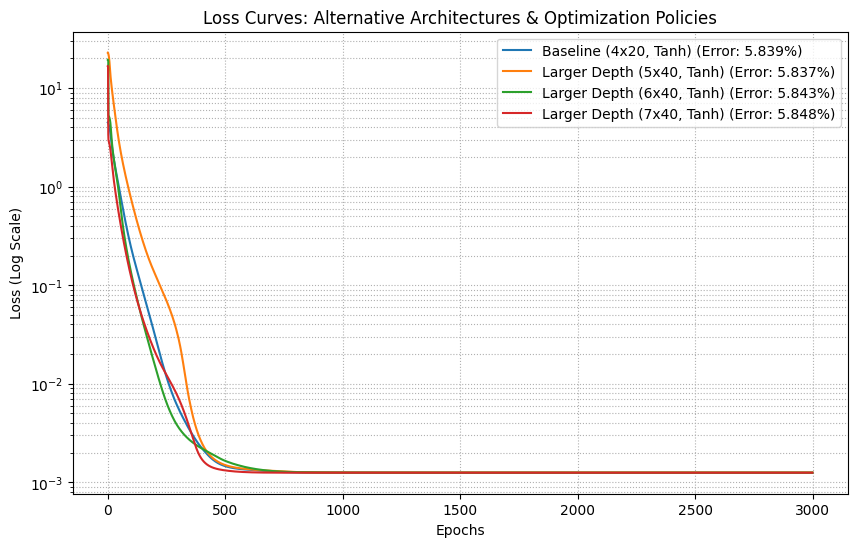

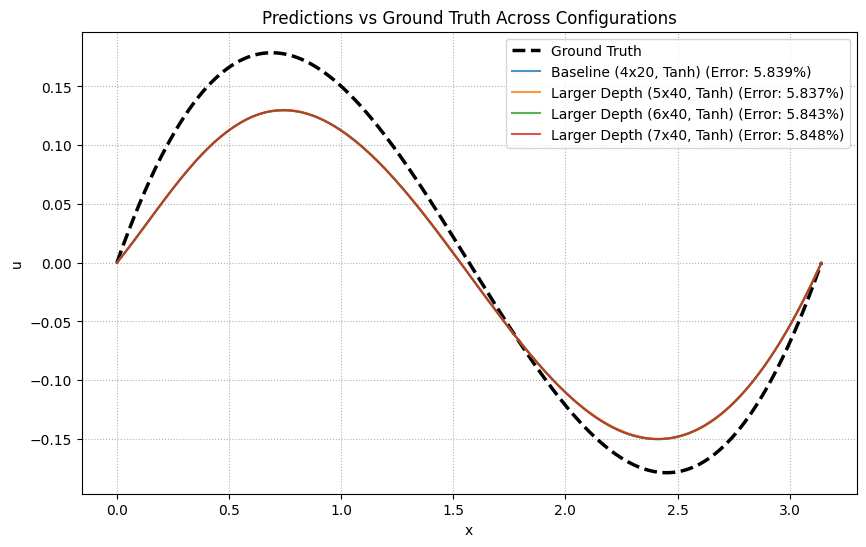

In [73]:
# Compare performance across all alternative strategies
plt.figure(figsize=(10, 6))
for name, res in exp_results.items():
    plt.plot(res["history"], label=f"{name} (Error: {res['error_pct']:.3f}%)")
plt.yscale("log")
plt.xlabel("Epochs")
plt.ylabel("Loss (Log Scale)")
plt.title("Loss Curves: Alternative Architectures & Optimization Policies")
plt.legend()
plt.grid(True, which="both", ls=":")
plt.show()

# Plot Predictions vs Ground Truth for each experiment
plt.figure(figsize=(10, 6))
plt.plot(x_test.numpy(), p_test.numpy(), 'k--', label="Ground Truth", lw=2.5)
for name, res in exp_results.items():
    plt.plot(x_test.numpy(), res["predictions"], label=f"{name} (Error: {res['error_pct']:.3f}%)", alpha=0.8)

plt.xlabel("x")
plt.ylabel("u")
plt.title("Predictions vs Ground Truth Across Configurations")
plt.legend()
plt.grid(True, which="both", ls=":")
plt.show()